# Clustered TSP com metaheurísticas híbridas

**GRASP + Algoritmo Genético + VNS + Simulated Annealing**

No **Clustered Traveling Salesman Problem (CTSP)** as cidades estão divididas em clusters e o caixeiro
precisa visitar todas as cidades de um cluster **em sequência**, antes de passar para o próximo.
O objetivo é o mesmo do TSP: minimizar a distância total do ciclo.

Este notebook mostra o passo a passo do algoritmo. O código está no pacote `ctsp/` e o experimento completo roda com `python main.py`.

## Setup

Rode o notebook a partir da raiz do repositório (com as dependências do `requirements.txt` instaladas).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ctsp import (read_tsp_file, build_cost_matrix, calc_of, check_solution_viability,
                  generate_initial_solutions_GRASP, VNS, SA, GA, run_hybrid, set_seed)
from ctsp.plots import plot_route, plot_convergence

set_seed(0)

## Instância

Formato do CSV: `X`, `Y`, `cluster` e a matriz de distâncias (`0, 1, ..., n-1`).
Para converter instâncias da GTSPLIB ou gerar novas, veja `scripts/instances.py`.

50 cidades, 4 clusters


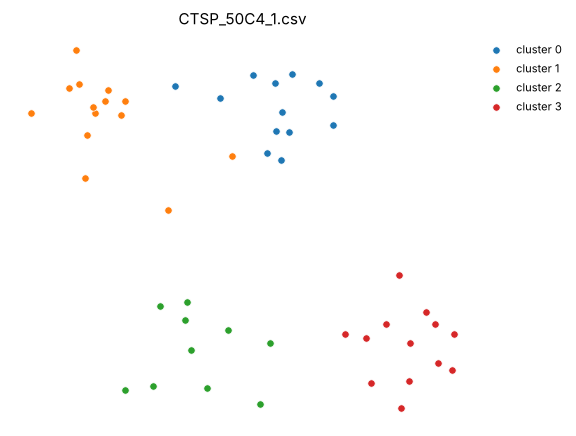

In [2]:
instance = 'data/CTSP_50C4_1.csv'
coords, cluster, tsp_distance = read_tsp_file(instance)

print(f"{len(cluster)} cidades, {len(np.unique(cluster))} clusters")
plot_route(coords, cluster, title=instance.split('/')[-1]);

## Penalização da troca de cluster

Em vez de proibir rotas inviáveis, cada aresta que troca de cluster recebe uma penalização $M$:

$$C_{ij} = d_{ij} + M \cdot \mathbb{1}[\text{cluster}_i \neq \text{cluster}_j]$$

Num ciclo viável cada cluster é visitado em um único bloco, então há exatamente $k$ trocas ($k$ = nº de clusters).
Qualquer rota inviável tem pelo menos $k+1$. Com $M > n \cdot \max(d)$, **toda rota viável custa menos que qualquer inviável**,
e o ótimo do problema penalizado é o ótimo do CTSP.

In [3]:
tsp_distance_punished, M = build_cost_matrix(tsp_distance, cluster)
print(f"M = {M:.2f}")

M = 45.98


## Soluções iniciais com GRASP

A cada passo, a próxima cidade é sorteada na RCL: candidatas com custo $\le c_{min} + \alpha (c_{max} - c_{min})$.
$\alpha = 0$ é o vizinho mais próximo; $\alpha = 1$ é aleatório.

In [4]:
solutions_list = generate_initial_solutions_GRASP(tsp_distance_punished, 10, alphas=[0.25, 0.5, 0.75])

initial_of = [calc_of(s, tsp_distance) for s in solutions_list]
initial_viable = [check_solution_viability(s, cluster) for s in solutions_list]
pd.DataFrame({'OF (distância real)': initial_of, 'Viável': initial_viable}).describe(include='all')

,OF (distância real),Viável
count,10.000000,10
unique,NaN,1
top,NaN,True
freq,NaN,10
mean,7.487919,NaN
std,0.698077,NaN
min,6.423272,NaN
25%,7.141731,NaN
50%,7.334844,NaN
75%,7.871579,NaN


## Cada metaheurística isolada

Aplicando VNS, SA e GA na melhor solução do GRASP para ver a contribuição de cada uma.

In [5]:
best_initial = solutions_list[int(np.argmin([calc_of(s, tsp_distance_punished) for s in solutions_list]))]

VNS_solution, _ = VNS(best_initial, tsp_distance_punished)
SA_Solution, _ = SA(best_initial, tsp_distance_punished, M=M)
GA_solutions, _ = GA(solutions_list, tsp_distance_punished, 0.10, 76, 10)

pd.DataFrame({
    'Método': ['GRASP', 'VNS', 'SA', 'GA'],
    'OF': [calc_of(s, tsp_distance) for s in [best_initial, VNS_solution, SA_Solution, GA_solutions[0]]],
    'Viável': [check_solution_viability(s, cluster) for s in [best_initial, VNS_solution, SA_Solution, GA_solutions[0]]],
}).round(4)

,Método,OF,Viável
0,GRASP,6.4233,True
1,VNS,5.1954,True
2,SA,4.0606,True
3,GA,6.2436,True


## Algoritmo híbrido

A cada iteração: VNS e SA em cada solução da população, GA na população inteira, e as melhores soluções distintas seguem para a próxima iteração.
O algoritmo para em `Max_itters` ou quando passa 30 iterações seguidas sem melhorar a melhor OF.

Solução válida? True
OF (distância real): 3.8134


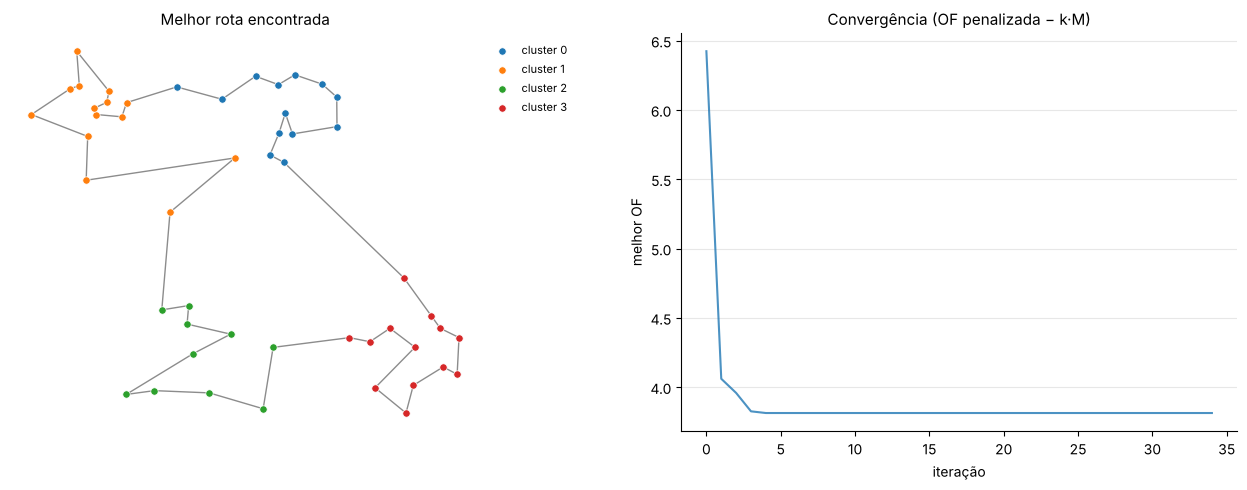

In [6]:
best_SOL, best_OF, history = run_hybrid(tsp_distance_punished, {'Max_itters': 50, 'M': M}, seed=0)

print(f"Solução válida? {check_solution_viability(best_SOL, cluster)}")
print(f"OF (distância real): {calc_of(best_SOL, tsp_distance):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_route(coords, cluster, best_SOL, ax=axes[0], title='Melhor rota encontrada')
## a OF penalizada de uma rota viável é a distância + k·M, então subtraindo k·M a curva fica na escala da distância
k = len(np.unique(cluster))
plot_convergence([np.array(history) - k * M], ax=axes[1], title='Convergência (OF penalizada − k·M)')
plt.tight_layout()

## Robustez: várias runs

Metaheurísticas são estocásticas, então um único resultado não diz muito. Rodando com sementes diferentes
para olhar a distribuição da OF (o `main.py` faz isso para todas as instâncias e salva em `results/`).

count    10.0000
mean      3.8230
std       0.0121
min       3.8134
25%       3.8134
50%       3.8194
75%       3.8285
max       3.8502

Runs viáveis: 100%


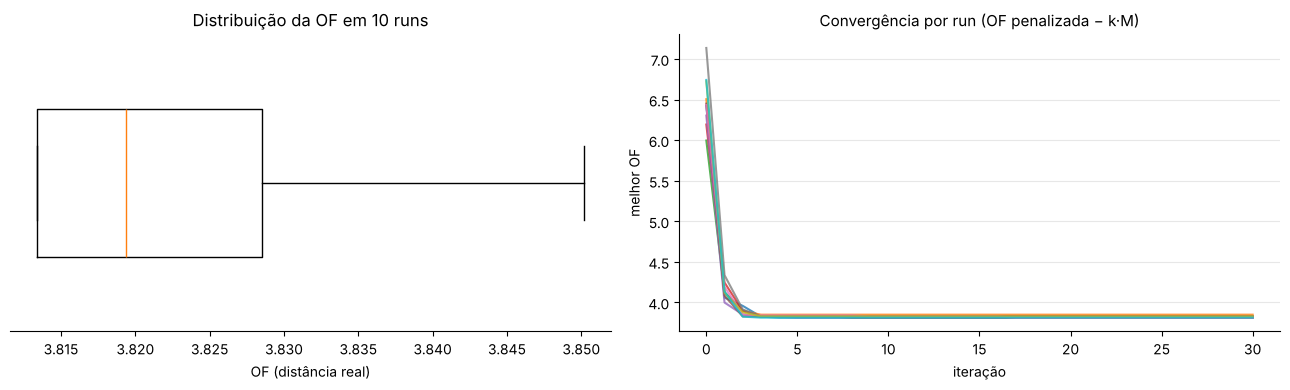

In [7]:
runs = 10
results = []
histories = []
for seed in range(runs):
    sol, _, hist = run_hybrid(tsp_distance_punished, {'Max_itters': 30, 'M': M}, seed=seed)
    results.append({'seed': seed, 'OF': calc_of(sol, tsp_distance), 'Viável': check_solution_viability(sol, cluster)})
    histories.append(hist)

results = pd.DataFrame(results)
print(results['OF'].describe().round(4).to_string())
print(f"\nRuns viáveis: {results['Viável'].mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].boxplot(results['OF'], orientation='horizontal', widths=0.5)
axes[0].set_yticks([]); axes[0].set_xlabel('OF (distância real)'); axes[0].set_title('Distribuição da OF em 10 runs')
axes[0].spines[['top', 'right', 'left']].set_visible(False)
plot_convergence([np.array(h) - k * M for h in histories], ax=axes[1], title='Convergência por run (OF penalizada − k·M)')
plt.tight_layout()